# 01 · Dataset preparation & text → embedding pipeline
**Milestone 1 — From Words to Worlds (IE 7615)**

What this notebook does:
1. Downloads **COCO 2017 val** (5,000 images, ~25k captions)
2. Cleans captions and builds image–caption pairs
3. Resizes / center-crops images to **512×512**
4. Encodes captions with **CLIP ViT-L/14** (the same text encoder Stable Diffusion 1.5 uses) and caches the embeddings
5. Sanity-checks the embeddings with a quick text→image retrieval test

> Colab: *Runtime → Change runtime type → GPU (T4 is enough).*

In [1]:
# --- Setup: works in Google Colab and locally ---
import os, sys
from pathlib import Path

REPO_URL = "https://github.com/YOUR_USERNAME/words-to-worlds.git"   # <-- change to your repo
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("words-to-worlds").exists():
        !git clone -q {REPO_URL}
    %cd words-to-worlds
    !pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":
    os.chdir("..")              # run from repo root locally

sys.path.insert(0, os.getcwd())
print("Working dir:", os.getcwd())

Working dir: /Users/hiralr/Desktop/Generative_Project_DeepLearning/Generative_Project_DeepLearning


## 1. Download COCO 2017 val (~1.3 GB, skipped if already present)

In [2]:
from src import config as C

if not C.COCO_CAPTIONS.exists():
    !bash scripts/download_coco.sh
print("Images found:", len(list(C.COCO_IMAGES.glob("*.jpg"))))

Images found: 5000


## 2. Load and clean captions

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_coco_captions, clean_captions, build_pairs, sample_subset

raw = load_coco_captions(C.COCO_CAPTIONS)
clean = clean_captions(raw, min_words=C.MIN_CAPTION_WORDS)

print(f"Raw captions:   {len(raw):,}")
print(f"Clean captions: {len(clean):,}  (dropped {len(raw) - len(clean):,})")
print(f"Images:         {clean.image_id.nunique():,}")
clean.head()

Raw captions:   25,014
Clean captions: 25,000  (dropped 14)
Images:         5,000


,image_id,file_name,caption,n_words
0,179765,000000179765.jpg,A black Honda motorcycle parked in front of a ...,10
1,179765,000000179765.jpg,A Honda motorcycle parked in a grass driveway,8
2,190236,000000190236.jpg,An office cubicle with four different types of...,9
3,331352,000000331352.jpg,A small closed toilet in a cramped space,8
4,517069,000000517069.jpg,Two women waiting at a bench next to a street,10


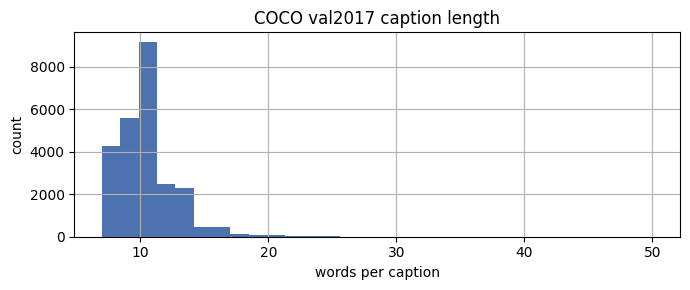

count    25000.0
mean        10.4
std          2.3
min          7.0
25%          9.0
50%         10.0
75%         11.0
max         50.0
Name: n_words, dtype: float64


In [4]:
# Caption length distribution (useful for the report)
fig, ax = plt.subplots(figsize=(7, 3))
clean["n_words"].hist(bins=30, ax=ax, color="#4C72B0")
ax.set(title="COCO val2017 caption length", xlabel="words per caption", ylabel="count")
plt.tight_layout(); plt.show()
print(clean["n_words"].describe().round(1))

## 3. Build image–caption pairs
One **primary caption** per image (used as the prompt) plus **all captions** (kept as references for alignment scoring).
We save the full 5k set and a reproducible 1k subset for fast experiments.

In [5]:
pairs = build_pairs(clean, seed=C.SEED)
subset = sample_subset(pairs, C.SUBSET_SIZE, seed=C.SEED)

C.PROC_DIR.mkdir(parents=True, exist_ok=True)
pairs.to_json(C.PROC_DIR / "pairs_5k.json", orient="records", indent=1)
subset.to_json(C.PROC_DIR / "pairs_1k.json", orient="records", indent=1)
print(f"Full: {len(pairs):,} pairs | Subset: {len(subset):,} pairs")
subset[["image_id", "file_name", "caption", "n_refs"]].head()

Full: 5,000 pairs | Subset: 1,000 pairs


,image_id,file_name,caption,n_refs
0,885,000000000885.jpg,A male tennis player in white shorts is playin...,5
1,1353,000000001353.jpg,Some children are riding on a mini orange train,5
2,1584,000000001584.jpg,A red double decker bus that is in the middle ...,5
3,1761,000000001761.jpg,Two airplanes flying in the sky above a black ...,5
4,2149,000000002149.jpg,A white bowl of green granny smith apples,5


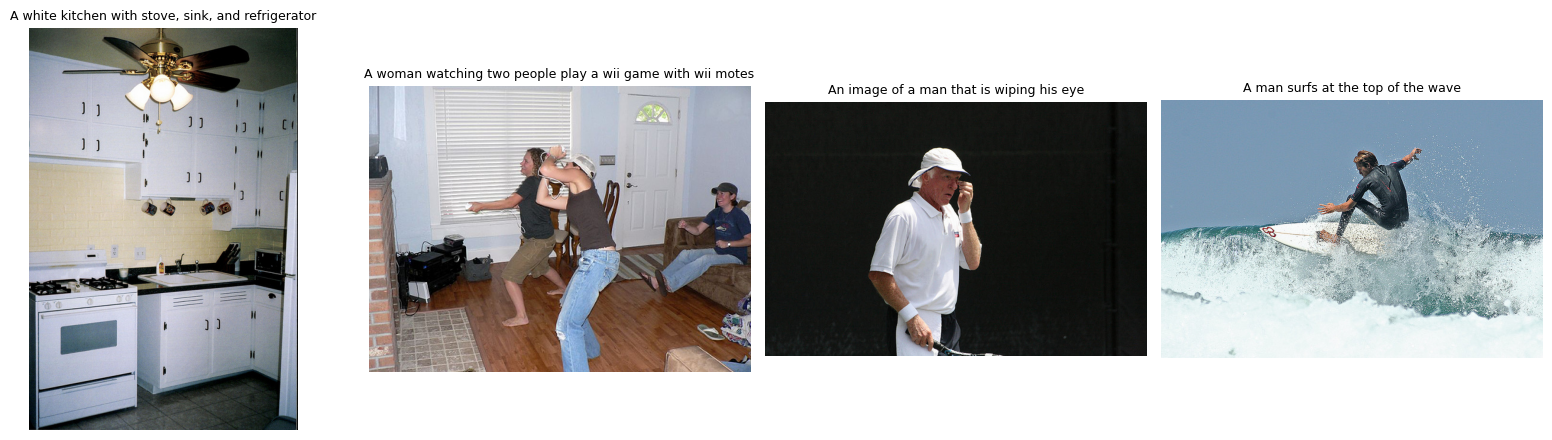

In [6]:
# Look at a few pairs
from src.data import load_image
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (_, row) in zip(axes, subset.sample(4, random_state=1).iterrows()):
    ax.imshow(load_image(C.COCO_IMAGES / row.file_name)); ax.axis("off")
    ax.set_title(row.caption[:60] + ("…" if len(row.caption) > 60 else ""), fontsize=9, wrap=True)
plt.tight_layout(); plt.show()

## 4. Resize + center-crop images to 512×512

In [7]:
from src.data import preprocess_images, resize_center_crop

IMG_OUT = C.PROC_DIR / f"images_{C.IMAGE_SIZE}"
PROCESS_FULL_SET = True   # 5k images ≈ 1–2 min; needed later as FID reference set

target = pairs if PROCESS_FULL_SET else subset
failed = preprocess_images(target, C.COCO_IMAGES, IMG_OUT, size=C.IMAGE_SIZE)
print(f"Saved to {IMG_OUT} | failed: {len(failed)}")

/opt/miniconda3/envs/mlops_lab3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Preprocessing images: 100%|██████████| 5000/5000 [00:00<00:00, 58643.39it/s]

Saved to /Users/hiralr/Desktop/Generative_Project_DeepLearning/Generative_Project_DeepLearning/data/processed/images_512 | failed: 0


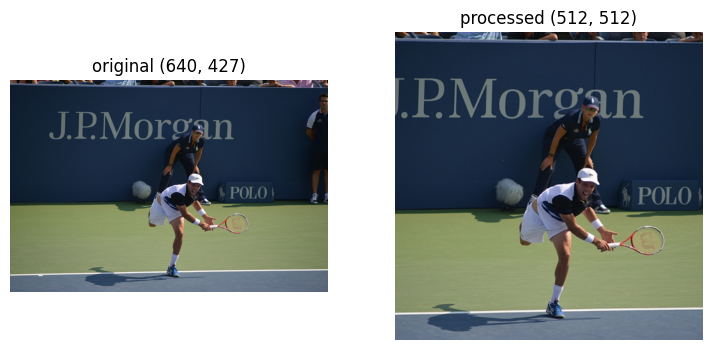

tensor: (3, 512, 512) range: -1.0 to 1.0


In [8]:
# Before / after check
row = subset.iloc[0]
orig = load_image(C.COCO_IMAGES / row.file_name)
proc = load_image(IMG_OUT / row.file_name)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(orig); ax[0].set_title(f"original {orig.size}"); ax[0].axis("off")
ax[1].imshow(proc); ax[1].set_title(f"processed {proc.size}"); ax[1].axis("off")
plt.show()

# Normalisation to [-1, 1] happens when tensors are created (what the SD VAE expects)
from src.data import to_model_tensor
t = to_model_tensor(proc)
print("tensor:", tuple(t.shape), "range:", round(t.min().item(), 2), "to", round(t.max().item(), 2))

## 5. Text → CLIP embeddings
- **hidden** `(N, 77, 768)` — per-token states, what the SD U-Net reads through cross-attention
- **pooled** `(N, 768)` — normalised sentence embedding, for CLIP score and retrieval

We cache *hidden* for the 1k subset (~120 MB) and *pooled* for all 5k.

In [9]:
import torch
from src.embeddings import ClipEncoder

enc = ClipEncoder(C.CLIP_MODEL)
print("Device:", enc.device)
print("Captions longer than 77 tokens (truncated):", enc.count_truncated(pairs["caption"].tolist()))

hidden_1k, pooled_1k = enc.encode_text(subset["caption"].tolist())
_, pooled_5k = enc.encode_text(pairs["caption"].tolist(), return_hidden=False)
print("hidden_1k:", tuple(hidden_1k.shape), hidden_1k.dtype)
print("pooled_5k:", tuple(pooled_5k.shape))

torch.save({"image_ids": subset.image_id.tolist(), "captions": subset.caption.tolist(),
            "hidden": hidden_1k, "pooled": pooled_1k}, C.PROC_DIR / "clip_text_1k.pt")
torch.save({"image_ids": pairs.image_id.tolist(), "captions": pairs.caption.tolist(),
            "pooled": pooled_5k}, C.PROC_DIR / "clip_text_5k_pooled.pt")
print("Saved embeddings to", C.PROC_DIR)

W1106 00:27:04.237000 70505 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 590/590 [00:00<00:00, 9270.19it/s]


Device: cpu
Captions longer than 77 tokens (truncated): 0
hidden_1k: (1000, 77, 768) torch.float16
pooled_5k: (5000, 768)
Saved embeddings to /Users/hiralr/Desktop/Generative_Project_DeepLearning/Generative_Project_DeepLearning/data/processed


## 6. Sanity check: do the embeddings understand the images?
Text→image retrieval on the 1k subset: for each caption, is its true image ranked top-1 / top-5 among 1,000?
Random chance is 0.1% for R@1. A working pipeline should be far above that.

{'R@1': '53.6%', 'R@5': '82.7%', 'R@10': '90.3%'}


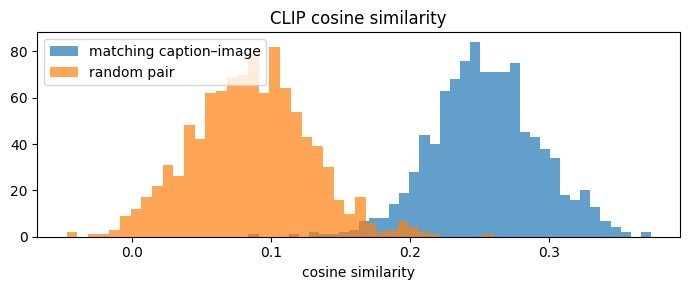

mean matching: 0.254 | mean random: 0.086


In [10]:
from src.embeddings import retrieval_recall

images_1k = [load_image(IMG_OUT / fn) for fn in subset.file_name]
img_feats = enc.encode_images(images_1k)
print({k: f"{v:.1%}" for k, v in retrieval_recall(img_feats, pooled_1k).items()})

# Matching-pair vs random-pair similarity (also a baseline for CLIP score later)
sims = (pooled_1k * img_feats).sum(1)
rand = (pooled_1k * img_feats[torch.randperm(len(img_feats))]).sum(1)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(sims.numpy(), bins=40, alpha=.7, label="matching caption–image")
ax.hist(rand.numpy(), bins=40, alpha=.7, label="random pair")
ax.set(title="CLIP cosine similarity", xlabel="cosine similarity"); ax.legend()
plt.tight_layout(); plt.show()
print(f"mean matching: {sims.mean():.3f} | mean random: {rand.mean():.3f}")

## Summary (fill in after running)
| Item | Value |
|---|---|
| Clean captions | |
| Image–caption pairs | 5,000 (1,000 subset) |
| Truncated captions (>77 tokens) | |
| Retrieval R@1 / R@5 (1k) | |
| Mean CLIP sim (match vs random) | |

Next: `02_baseline_samples.ipynb` generates images from these cached embeddings.